In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier
)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Change these two values
df = pd.read_csv("stock_data.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())
print(df["Target"].value_counts())

Matplotlib is building the font cache; this may take a moment.


       Open     Close      High       Low    Volume       RSI      MACD  \
0  0.374639  0.374780  0.373510  0.378390  0.298909  0.847286  0.741715   
1  0.950982  0.937746  0.938422  0.946158  0.094805  0.494543  0.881343   
2  0.732198  0.719825  0.723644  0.723158  0.126348  0.195471  0.463179   
3  0.598823  0.599865  0.596973  0.605322  0.180662  0.736684  0.289076   
4  0.156053  0.163410  0.155891  0.166084  0.203646  0.418698  0.318761   

   Bollinger_Upper  Bollinger_Lower  Sentiment_Score  GDP_Growth  \
0         0.367146         0.366420         0.877177    0.580868   
1         0.938396         0.935640         0.907192    0.527044   
2         0.710666         0.702300         0.378363    0.351052   
3         0.593793         0.586936         0.231614    0.493274   
4         0.164158         0.156355         0.191642    0.365116   

   Inflation_Rate  Target  
0        0.038604       0  
1        0.108908       0  
2        0.432540       0  
3        0.946349       0  


In [2]:
# Remove rows with missing target labels
df = df.dropna(subset=["Target"]).copy()

X = df.drop(columns=["Target"])
y = df["Target"]

# Encode target labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Identify feature types
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Numerical preprocessing
num_imputer = SimpleImputer(strategy="median")
X_train_num = num_imputer.fit_transform(X_train[numeric_cols])
X_test_num = num_imputer.transform(X_test[numeric_cols])

scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

# Categorical preprocessing
if categorical_cols:
    cat_imputer = SimpleImputer(strategy="most_frequent")
    X_train_cat = cat_imputer.fit_transform(X_train[categorical_cols])
    X_test_cat = cat_imputer.transform(X_test[categorical_cols])

    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    X_train_cat = encoder.fit_transform(X_train_cat)
    X_test_cat = encoder.transform(X_test_cat)

    X_train_scaled = np.hstack([X_train_num, X_train_cat])
    X_test_scaled = np.hstack([X_test_num, X_test_cat])
else:
    X_train_scaled = X_train_num
    X_test_scaled = X_test_num

class_labels = np.arange(len(label_encoder.classes_))

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("Classes:", label_encoder.classes_)

Training shape: (8000, 12)
Testing shape: (2000, 12)
Classes: [0 1]


In [3]:
results = []
trained_models = {}
predictions = {}

def evaluate_model(name, model):
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    weighted_f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    # ROC-AUC
    try:
        if len(class_labels) == 2:
            roc_auc = roc_auc_score(y_test, y_prob[:, 1])
        else:
            roc_auc = roc_auc_score(
                y_test,
                y_prob,
                labels=class_labels,
                multi_class="ovr",
                average="weighted"
            )
    except ValueError:
        roc_auc = np.nan

    cm = confusion_matrix(y_test, y_pred, labels=class_labels)

    print("\n")
    print(name)
   
    print("Accuracy:", round(accuracy, 4))
    print("Precision (weighted):", round(precision, 4))
    print("Recall (weighted):", round(recall, 4))
    print("F1-score (weighted):", round(weighted_f1, 4))
    print("ROC-AUC:", round(roc_auc, 4) if not np.isnan(roc_auc) else "Undefined")

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        labels=class_labels,
        target_names=[str(c) for c in label_encoder.classes_],
        zero_division=0
    ))

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Weighted F1": weighted_f1,
        "ROC-AUC": roc_auc
    })

    trained_models[name] = model
    predictions[name] = y_pred

    return model



Logistic Regression
Accuracy: 0.942
Precision (weighted): 0.9454
Recall (weighted): 0.942
F1-score (weighted): 0.9153
ROC-AUC: 0.9437

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      1881
           1       1.00      0.03      0.05       119

    accuracy                           0.94      2000
   macro avg       0.97      0.51      0.51      2000
weighted avg       0.95      0.94      0.92      2000



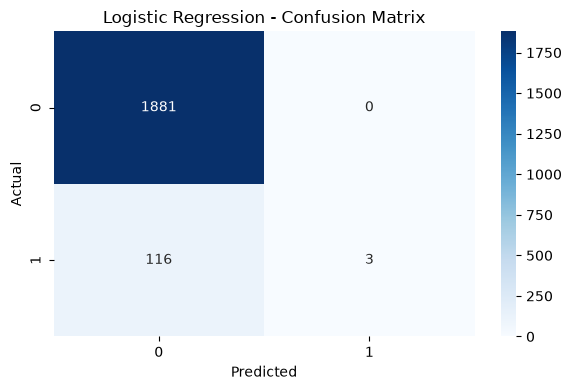



KNN
Accuracy: 0.9285
Precision (weighted): 0.9016
Recall (weighted): 0.9285
F1-score (weighted): 0.9127
ROC-AUC: 0.7573

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      1881
           1       0.23      0.08      0.12       119

    accuracy                           0.93      2000
   macro avg       0.59      0.53      0.54      2000
weighted avg       0.90      0.93      0.91      2000



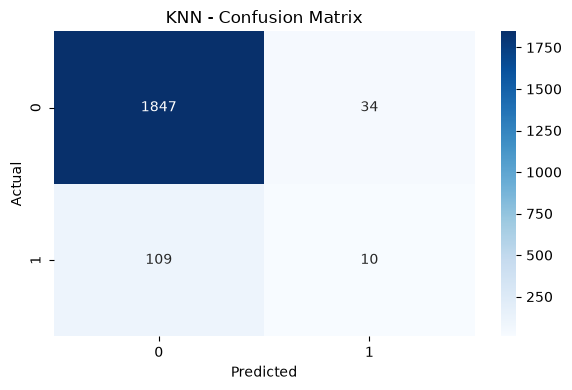



Naive Bayes
Accuracy: 0.787
Precision (weighted): 0.9486
Recall (weighted): 0.787
F1-score (weighted): 0.8414
ROC-AUC: 0.899

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.78      0.87      1881
           1       0.21      0.94      0.34       119

    accuracy                           0.79      2000
   macro avg       0.60      0.86      0.61      2000
weighted avg       0.95      0.79      0.84      2000



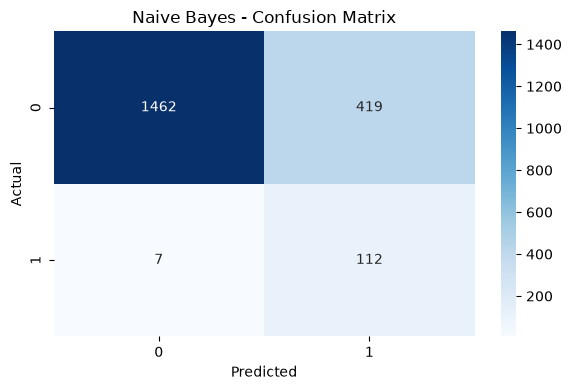



Decision Tree
Accuracy: 0.956
Precision (weighted): 0.9547
Recall (weighted): 0.956
F1-score (weighted): 0.9553
ROC-AUC: 0.7877

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1881
           1       0.64      0.60      0.62       119

    accuracy                           0.96      2000
   macro avg       0.81      0.79      0.80      2000
weighted avg       0.95      0.96      0.96      2000



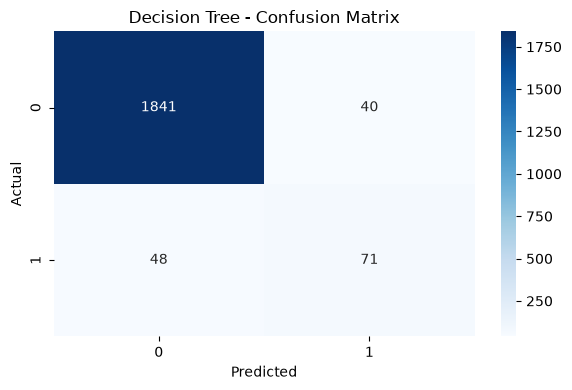

c:\Users\tejas\Documents\Stock-Market-Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(




SVM
Accuracy: 0.9405
Precision (weighted): 0.8845
Recall (weighted): 0.9405
F1-score (weighted): 0.9117
ROC-AUC: 0.9694

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      1881
           1       0.00      0.00      0.00       119

    accuracy                           0.94      2000
   macro avg       0.47      0.50      0.48      2000
weighted avg       0.88      0.94      0.91      2000



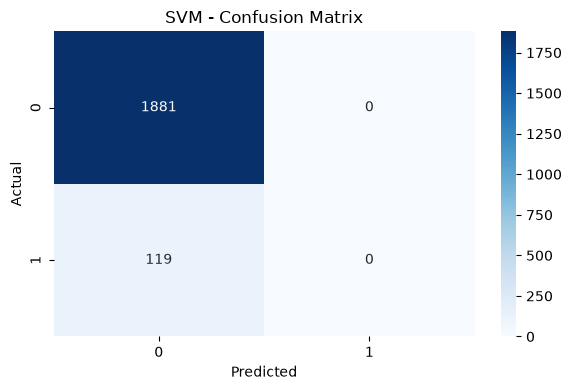

In [4]:
# 1. Logistic Regression
lr_model = evaluate_model(
    "Logistic Regression",
    LogisticRegression(max_iter=2000, random_state=42)
)

# 2. K-Nearest Neighbors
knn_model = evaluate_model(
    "KNN",
    KNeighborsClassifier(n_neighbors=5, metric="minkowski")
)

# 3. Naive Bayes (Gaussian)
nb_model = evaluate_model(
    "Naive Bayes",
    GaussianNB()
)

# 4. Decision Tree
dt_model = evaluate_model(
    "Decision Tree",
    DecisionTreeClassifier(max_depth=None, random_state=42)
)

# 5. Support Vector Machine
svm_model = evaluate_model(
    "SVM",
    SVC(C=1.0, kernel="rbf", probability=True, random_state=42)
)



Random Forest
Accuracy: 0.9595
Precision (weighted): 0.9601
Recall (weighted): 0.9595
F1-score (weighted): 0.9499
ROC-AUC: 0.9673

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      1881
           1       0.97      0.33      0.49       119

    accuracy                           0.96      2000
   macro avg       0.97      0.66      0.73      2000
weighted avg       0.96      0.96      0.95      2000



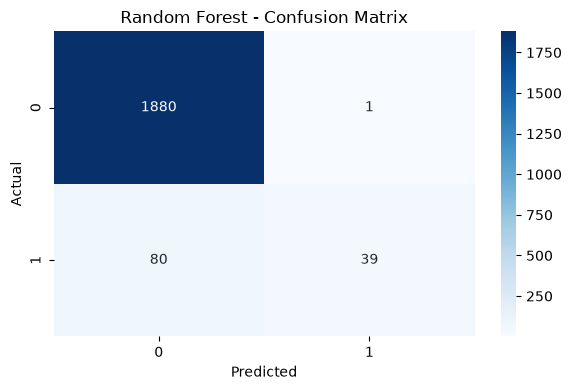

In [5]:
# 6. Random Forest
rf_model = evaluate_model(
    "Random Forest",
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
)
